In [24]:
import numpy as np
import pandas as pd
from scipy import stats

from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, LabelEncoder
from sklearn.model_selection import train_test_split

In [22]:
import pandas as pd
df=pd.read_csv('patients_data.csv')
print(df.head())
print("\nDataframe Information:\n")
print(df.info())

    age genre  tension_systolique  cholesterol   imc       fumeur  \
0  61.0     F                 NaN        165.0   NaN          non   
1  53.0     F                 NaN        168.0  34.2          NaN   
2  63.0     M               142.0        230.0  29.5  occasionnel   
3  73.0     F               124.0        192.0  95.0     régulier   
4  52.0     F               126.0        165.0  30.1  occasionnel   

        region  nb_visites  diagnostic  
0        Alger           2           1  
1        Blida           3           0  
2  Constantine           1           1  
3       Béjaïa           3           1  
4  Constantine           5           1  

Dataframe Information:

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   age                 470 non-null    float64
 1   genre               500 non-null    str    
 2   tension_systolique  

              age  tension_systolique  cholesterol         imc  nb_visites  \
count  470.000000          468.000000   469.000000  464.000000  500.000000   
mean    56.078723          124.467949   197.586354   27.379310    2.936000   
std     16.488808           24.199055    43.846999    7.034138    1.643565   
min     18.000000            5.000000     0.000000   15.000000    0.000000   
25%     47.000000          115.000000   178.000000   24.100000    2.000000   
50%     55.000000          124.000000   195.000000   27.000000    3.000000   
75%     63.000000          133.000000   213.000000   30.000000    4.000000   
max    200.000000          400.000000   800.000000   95.000000    8.000000   

       diagnostic  
count  500.000000  
mean     0.470000  
std      0.499599  
min      0.000000  
25%      0.000000  
50%      0.000000  
75%      1.000000  
max      1.000000  


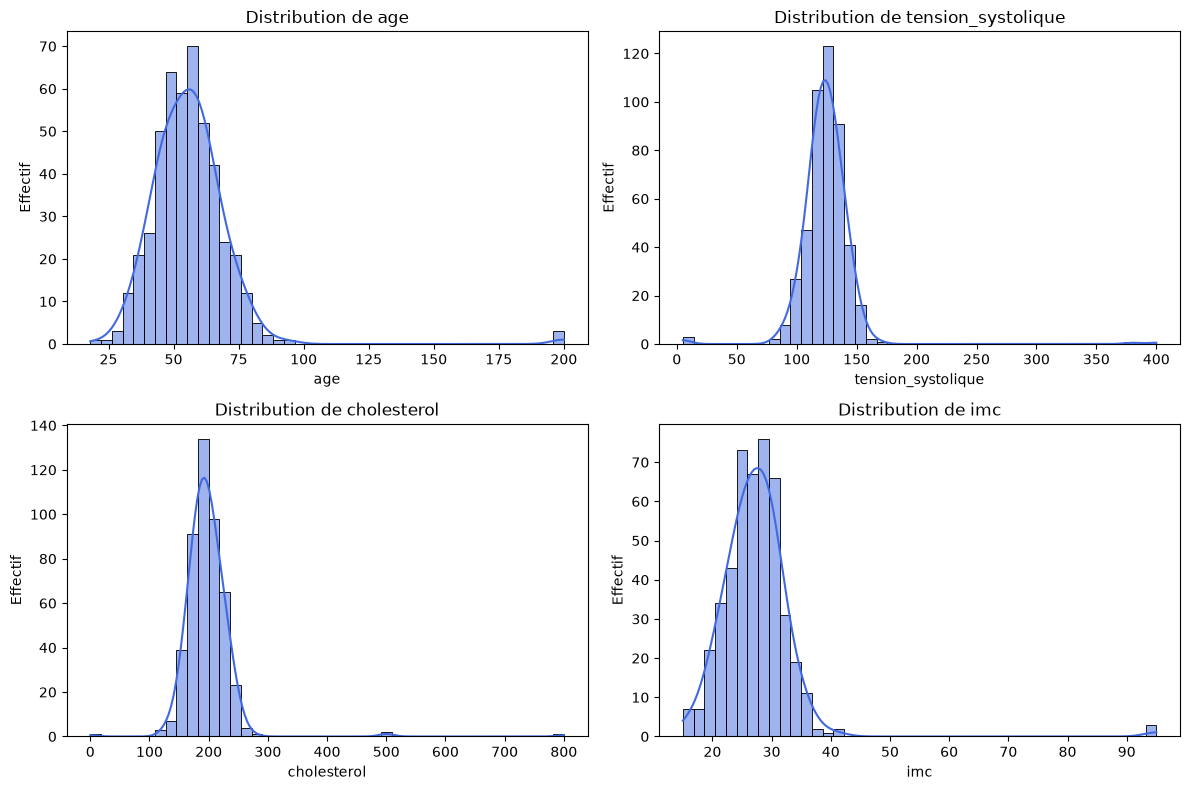

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns
print(df.describe())
num_vars=['age','tension_systolique','cholesterol','imc']
fig,axes=plt.subplots(2,2,figsize=(12,8))
axes=axes.flatten()
for i,col in enumerate(num_vars):
    sns.histplot(df[col].dropna(), kde=True, ax=axes[i],color='royalblue')
    axes[i].set_title(f'Distribution de {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Effectif")

plt.tight_layout()
plt.show()

                    Nb Manquents  Pourcentage (%)
age                           30              6.0
genre                          0              0.0
tension_systolique            32              6.4
cholesterol                   31              6.2
imc                           36              7.2
fumeur                        18              3.6
region                        20              4.0
nb_visites                     0              0.0
diagnostic                     0              0.0


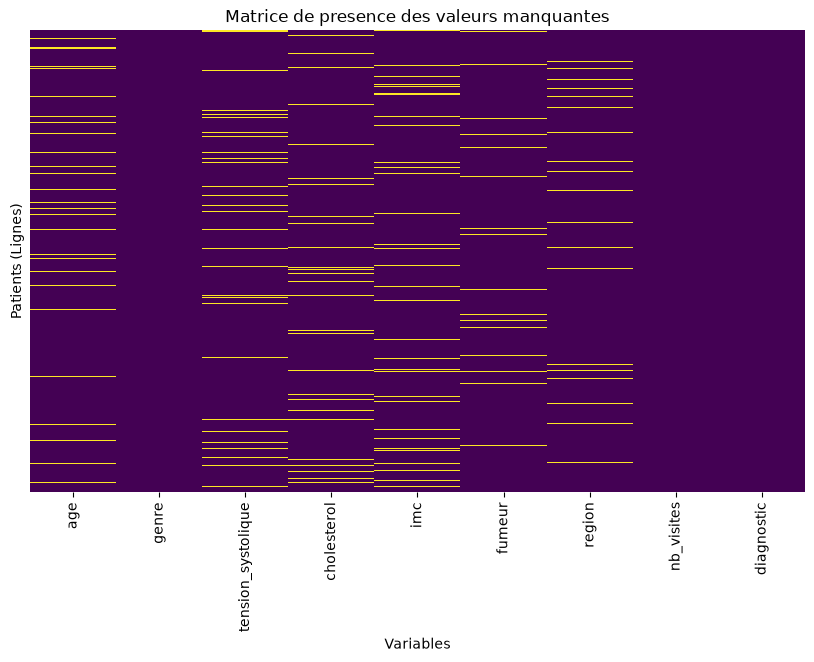

In [48]:
missing_count=df.isnull().sum()
missing_percent=df.isnull().mean()*100

missing_df=pd.DataFrame({
    'Nb Manquents' : missing_count,
    'Pourcentage (%)': missing_percent
})
print(missing_df)

plt.figure(figsize=(10,6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Matrice de presence des valeurs manquantes')
plt.xlabel('Variables')
plt.ylabel('Patients (Lignes)')
plt.show()